In [41]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import matplotlib.pyplot as plt
import numpy as np
import scipy
import copy

# hyperparameters
n_epochs = 3
batch_size_train = 64
batch_size_test = 1000
learning_rate = 0.01
momentum = 0.5
log_interval = 10

random_seed = 1
torch.backends.cudnn.enabled = False
torch.manual_seed(random_seed) 

# load Data
train_loader = torch.utils.data.DataLoader(
  torchvision.datasets.MNIST('/files/', train=True, download=True,
                             transform=torchvision.transforms.Compose([
                               torchvision.transforms.ToTensor(),
                               torchvision.transforms.Normalize(
                                 (0.1307,), (0.3081,))
                             ])),
  batch_size=batch_size_train, shuffle=True)

test_loader = torch.utils.data.DataLoader(
  torchvision.datasets.MNIST('/files/', train=False, download=True,
                             transform=torchvision.transforms.Compose([
                               torchvision.transforms.ToTensor(),
                               torchvision.transforms.Normalize(
                                 (0.1307,), (0.3081,))
                             ])),
  batch_size=batch_size_test, shuffle=True)

# plot some examples
examples = enumerate(test_loader)
batch_idx, (example_data, example_targets) = next(examples)
example_data.shape

# fig = plt.figure()
# for i in range(6):
#   plt.subplot(2,3,i+1)
#   plt.tight_layout()
#   plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
#   plt.title("Ground Truth: {}".format(example_targets[i]))
#   plt.xticks([])
#   plt.yticks([])
# fig

# build network
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(1, 10, kernel_size=5)
        self.conv2 = nn.Conv2d(10, 20, kernel_size=5)
        self.conv2_drop = nn.Dropout2d()
        self.fc1 = nn.Linear(320, 50)
        self.fc2 = nn.Linear(50, 10)

    def forward(self, x):
        x = F.relu(F.max_pool2d(self.conv1(x), 2))
        x = F.relu(F.max_pool2d(self.conv2_drop(self.conv2(x)), 2))
        x = x.view(-1, 320)
        x = F.relu(self.fc1(x))
        x = F.dropout(x, training=self.training)
        x = self.fc2(x)
        return F.log_softmax(x, dim=1)
    
# do Work
network = Net()
optimizer = optim.SGD(network.parameters(), lr=learning_rate, momentum=momentum)

train_losses = []
train_counter = []
test_losses = []
test_counter = [i*len(train_loader.dataset) for i in range(n_epochs + 1)]

def train(epoch):
  network.train()
  for batch_idx, (data, target) in enumerate(train_loader):
    optimizer.zero_grad()
    output = network(data)
    loss = F.nll_loss(output, target)
    loss.backward()
    optimizer.step()
    if batch_idx % log_interval == 0:
      print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
        epoch, batch_idx * len(data), len(train_loader.dataset),
        100. * batch_idx / len(train_loader), loss.item()))
      train_losses.append(loss.item())
      train_counter.append(
        (batch_idx*64) + ((epoch-1)*len(train_loader.dataset)))
      #torch.save(network.state_dict(), '/results/model.pth')
      #torch.save(optimizer.state_dict(), '/results/optimizer.pth')
      
def test():
  network.eval()
  test_loss = 0
  correct = 0
  with torch.no_grad():
    for data, target in test_loader:
      output = network(data)
      test_loss += F.nll_loss(output, target, reduction="sum").item()
      pred = output.data.max(1, keepdim=True)[1]
      correct += pred.eq(target.data.view_as(pred)).sum()
  test_loss /= len(test_loader.dataset)
  test_losses.append(test_loss)
  print('\nTest set: Avg. loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
    test_loss, correct, len(test_loader.dataset),
    100. * correct / len(test_loader.dataset)))
  
test()
for epoch in range(1, n_epochs + 1):
  train(epoch)
  test()



Test set: Avg. loss: 2.3096, Accuracy: 924/10000 (9%)

Train Epoch: 1 [0/60000 (0%)]	Loss: 2.313179
Train Epoch: 1 [640/60000 (1%)]	Loss: 2.300776
Train Epoch: 1 [1280/60000 (2%)]	Loss: 2.298872
Train Epoch: 1 [1920/60000 (3%)]	Loss: 2.276723
Train Epoch: 1 [2560/60000 (4%)]	Loss: 2.241102
Train Epoch: 1 [3200/60000 (5%)]	Loss: 2.248662
Train Epoch: 1 [3840/60000 (6%)]	Loss: 2.189547
Train Epoch: 1 [4480/60000 (7%)]	Loss: 2.146399
Train Epoch: 1 [5120/60000 (9%)]	Loss: 2.107701
Train Epoch: 1 [5760/60000 (10%)]	Loss: 2.011356
Train Epoch: 1 [6400/60000 (11%)]	Loss: 1.843857
Train Epoch: 1 [7040/60000 (12%)]	Loss: 1.758839
Train Epoch: 1 [7680/60000 (13%)]	Loss: 1.672644
Train Epoch: 1 [8320/60000 (14%)]	Loss: 1.687645
Train Epoch: 1 [8960/60000 (15%)]	Loss: 1.426628
Train Epoch: 1 [9600/60000 (16%)]	Loss: 1.284204
Train Epoch: 1 [10240/60000 (17%)]	Loss: 1.318824
Train Epoch: 1 [10880/60000 (18%)]	Loss: 1.445287
Train Epoch: 1 [11520/60000 (19%)]	Loss: 1.140658
Train Epoch: 1 [12160/6

Text(0, 0.5, 'negative log likelihood loss')

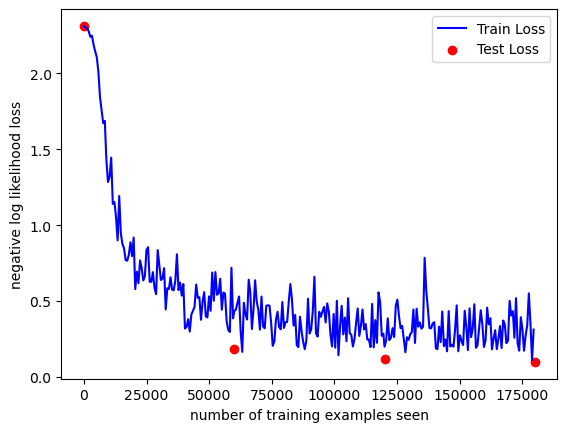

In [15]:
# evaluate

fig = plt.figure()
plt.plot(train_counter, train_losses, color='blue')
plt.scatter(test_counter, test_losses, color='red')
plt.legend(['Train Loss', 'Test Loss'], loc='upper right')
plt.xlabel('number of training examples seen')
plt.ylabel('negative log likelihood loss')
# fig

In [16]:
for name, param in network.named_parameters():
    if param.requires_grad:
        print(name)

conv1.weight
conv1.bias
conv2.weight
conv2.bias
fc1.weight
fc1.bias
fc2.weight
fc2.bias


In [54]:
# get parameters (all of them)
param_list = []
for el in network.parameters():
  param_list.append(el.data) # this (.data) acutally only takes the tensor and discards the object or whatever
  print(el.size())
print("\n")

param_list_SAVE = copy.deepcopy(param_list)

torch.Size([10, 1, 5, 5])
torch.Size([10])
torch.Size([20, 10, 5, 5])
torch.Size([20])
torch.Size([50, 320])
torch.Size([50])
torch.Size([10, 50])
torch.Size([10])




In [56]:
# reset parameters of OG net
counter = 0
for param in network.parameters():
  param.data = param_list_SAVE[counter]
  counter += 1

In [62]:
# play around

def test():
  network.eval()
  test_loss = 0
  correct = 0
  with torch.no_grad():
    for data, target in test_loader:
      output = network(data)
      test_loss += F.nll_loss(output, target, reduction="sum").item()
      pred = output.data.max(1, keepdim=True)[1]
      correct += pred.eq(target.data.view_as(pred)).sum()
  test_loss /= len(test_loader.dataset)
  test_losses.append(test_loss)
  print('\nTest set: Avg. loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
    test_loss, correct, len(test_loader.dataset),
    100. * correct / len(test_loader.dataset)))
  
def test_tweaked():
  network_tweaked.eval()
  test_loss = 0
  correct = 0
  with torch.no_grad():
    for data, target in test_loader:
      output = network_tweaked(data)
      test_loss += F.nll_loss(output, target, reduction="sum").item()
      pred = output.data.max(1, keepdim=True)[1]
      correct += pred.eq(target.data.view_as(pred)).sum()
  test_loss /= len(test_loader.dataset)
  test_losses.append(test_loss)
  print('\nTest set: Avg. loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
    test_loss, correct, len(test_loader.dataset),
    100. * correct / len(test_loader.dataset)))
  
# get parameters (all of them)
param_list = []
for el in network.parameters():
  param_list.append(el.data) #this acutally only takes the tensor and discards the object or whatever
  # print(el.size())
print("\n")
  
# copy the original net by value
network_tweaked = copy.deepcopy(network)

# print og network parameters (only the first layer tho 10x1x5x5)
print("OG network first layer\n", next(network.parameters())[0]) 
print("new network first layer\n", next(network_tweaked.parameters())[0])

test()
test_tweaked()

param_list_tweaked = copy.deepcopy(param_list)
# set new parameters equal to old ones (or tweaked parameter list!)
for i, el in enumerate(param_list_tweaked):
  size = el.size()
  param_list_tweaked[i] += 0.1 * (torch.rand(size) - 0.5*torch.ones(size))

counter = 0
for param in network_tweaked.parameters():
  param.data = param_list_tweaked[counter]
  counter += 1

print("OG\n", next(network.parameters())[0]) 
print("New\n", next(network_tweaked.parameters())[0])

test()
test_tweaked()

# 0.01 * rand( uniform[-0.5, 0.5] ) seems to equal about 1% of loss decrease




OG network first layer
 tensor([[[-0.1027,  0.2455,  0.1192,  0.2414,  0.1950],
         [ 0.0551,  0.1582,  0.1310,  0.1720,  0.0515],
         [-0.0681, -0.0585, -0.0147, -0.0600,  0.1590],
         [-0.0480, -0.1894, -0.2700, -0.1994, -0.1791],
         [-0.1525, -0.1098, -0.0590, -0.0623, -0.2615]]],
       grad_fn=<SelectBackward0>)
new network first layer
 tensor([[[-0.1027,  0.2455,  0.1192,  0.2414,  0.1950],
         [ 0.0551,  0.1582,  0.1310,  0.1720,  0.0515],
         [-0.0681, -0.0585, -0.0147, -0.0600,  0.1590],
         [-0.0480, -0.1894, -0.2700, -0.1994, -0.1791],
         [-0.1525, -0.1098, -0.0590, -0.0623, -0.2615]]],
       grad_fn=<SelectBackward0>)

Test set: Avg. loss: 0.0986, Accuracy: 9689/10000 (97%)


Test set: Avg. loss: 0.0986, Accuracy: 9689/10000 (97%)

OG
 tensor([[[-0.1027,  0.2455,  0.1192,  0.2414,  0.1950],
         [ 0.0551,  0.1582,  0.1310,  0.1720,  0.0515],
         [-0.0681, -0.0585, -0.0147, -0.0600,  0.1590],
         [-0.0480, -0.1894, -